# Laboratorio 11 · Guía 5 — Sistema de Pronóstico Directo a 30 Sesiones: Multisalida, Intervalos y Tablero

**Curso:** Minería de Datos (DM + AIAP) · FISI · UNMSM · Semestre 2026-II · **Semana 12 del sílabo (Tema 12: Modelos de Regresión)**
**Docente:** Prof. Mg. Ing. Ernesto D. Cancho-Rodríguez, MBA (GWU)

**Fase CRISP-DM:** Modelado · Evaluación · **Despliegue**.

**Pregunta de negocio:** el comité de inversiones pide «el precio de SPY dentro de 30 sesiones con un **rango**». Esta guía construye el **sistema completo**: un modelo **multisalida** que pronostica el retorno acumulado a **1, 2, …, 30** sesiones (estrategia **directa**), lo compara con referencias honestas, le pone **intervalos** cuya **cobertura** se mide, y **exporta** el resultado a un **tablero HTML** y a un archivo **JSON** que puede servir una API Flask.

**Estructura:** Parte I, estrategia directa frente a recursiva y **embargo** · Parte II, **cuatro modelos** multisalida y error por **horizonte** (**Mundo 1/3**) · Parte III, **intervalos** por cuantiles empíricos y por **cono de volatilidad** con su cobertura · Parte IV, **pronóstico final**, calendario bursátil, **JSON**, **CSV** y **tablero**.

> **Enfoque didáctico:** cada paso en su propia celda con sus `print`. Semilla `SEMILLA = 2026`. Precios hasta el 11-nov-2026. **No es asesoría de inversión.**

# PARTE I — Estrategia Directa, Objetivos Multi-horizonte y Embargo

## 1. Librerías, Semilla y Datos

Para pronosticar **h** pasos adelante hay dos estrategias: **recursiva** (un modelo a 1 paso que se realimenta con sus propias predicciones, acumulando error) y **directa** (un modelo por horizonte, o uno **multisalida** con 30 columnas objetivo). Aquí se usa la **directa multisalida**: la fila del día **t** tiene como objetivos los **retornos acumulados** de **t** a **t+h** para **h = 1…30**. Como cada fila «mira» 30 días adelante, entre el entrenamiento y la prueba se deja un **embargo** de **30 sesiones** para que ningún objetivo de entrenamiento use precios del período de prueba.

In [1]:
# Librerías del laboratorio
import warnings

warnings.filterwarnings("ignore")
import json
import numpy as np  # cálculo numérico
import pandas as pd  # tablas
import matplotlib.pyplot as plt  # gráficos
import yfinance as yf  # precios de Yahoo Finance
import sklearn, xgboost
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error

SEMILLA = 2026
rng = np.random.default_rng(SEMILLA)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 110
print(
    "scikit-learn",
    sklearn.__version__,
    "| XGBoost",
    xgboost.__version__,
    "| pandas",
    pd.__version__,
)

scikit-learn 1.3.1 | XGBoost 3.2.0 | pandas 2.2.3


In [2]:
# Precios de cierre ajustado de 28 activos (Yahoo Finance). Plan B: CSV de respaldo del curso (carpeta D03)
TICKERS = [
    "SPY",
    "QQQ",
    "XLK",
    "XLF",
    "XLE",
    "XLV",
    "XLY",
    "XLP",
    "XLI",
    "XLU",
    "XLB",
    "XLRE",
    "XLC",
    "GLD",
    "TLT",
    "AAPL",
    "MSFT",
    "JPM",
    "XOM",
    "CAT",
    "KO",
    "PFE",
    "BVN",
    "FSM",
    "SCCO",
    "BHP",
    "B",
    "^VIX",
]
ARCH = "26.11.12.cierres_ajustados_28_activos_2010-01-04_2026-11-11.csv"
try:
    precios = yf.download(
        TICKERS, start="2010-01-01", end="2026-11-12", auto_adjust=True, progress=False
    )["Close"].reindex(columns=TICKERS)
except Exception as e:
    precios = pd.DataFrame()
    print("Falló la descarga de Yahoo Finance:", e)
if precios.empty or precios["SPY"].notna().sum() < 4000:
    precios = pd.read_csv(
        ARCH, index_col=0, parse_dates=True
    )  # súbalo a Colab si Yahoo no responde
    print("Se usó el CSV de respaldo:", ARCH)
precios.index = pd.to_datetime(precios.index)
print(
    "Dimensiones:",
    precios.shape,
    "| desde",
    precios.index.min().date(),
    "hasta",
    precios.index.max().date(),
)
print(
    "Días con precio de SPY:",
    int(precios["SPY"].notna().sum()),
    "| último cierre de SPY:",
    round(float(precios["SPY"].iloc[-1]), 2),
)

Dimensiones: (4243, 28) | desde 2010-01-04 hasta 2026-11-11
Días con precio de SPY: 4241 | último cierre de SPY: 759.81


In [3]:
# Precios OHLCV (apertura, máximo, mínimo, cierre, volumen) ajustados de SPY. Plan B: CSV de respaldo (D03)
ARCH_SPY = "26.11.12.SPY_OHLCV_ajustado_2010-01-04_2026-11-11.csv"
try:
    spy = yf.download(
        "SPY", start="2010-01-01", end="2026-11-12", auto_adjust=True, progress=False
    )
    spy.columns = [c[0] if isinstance(c, tuple) else c for c in spy.columns]
    spy = spy[["Open", "High", "Low", "Close", "Volume"]]
except Exception as e:
    spy = pd.DataFrame()
    print("Falló la descarga de Yahoo Finance:", e)
if spy.empty or len(spy) < 4000:
    spy = pd.read_csv(ARCH_SPY, index_col=0, parse_dates=True)
    print("Se usó el CSV de respaldo:", ARCH_SPY)
spy.index = pd.to_datetime(spy.index)
print(
    "SPY OHLCV:",
    spy.shape,
    "| desde",
    spy.index.min().date(),
    "hasta",
    spy.index.max().date(),
)
print(spy.tail(3).round(2))

SPY OHLCV: (4241, 5) | desde 2010-01-04 hasta 2026-11-11
              Open    High     Low   Close    Volume
Date                                                
2026-11-09  741.95  755.42  741.03  752.69  50281200
2026-11-10  747.94  752.14  744.86  749.92  40698600
2026-11-11  756.80  762.51  754.90  759.81  38854000


## 2. Variables Causales y 30 Objetivos

In [4]:
# Variables conocidas al cierre de t (riesgo, momento y posición respecto a medias móviles) y 30 objetivos futuros
H = 30
cierre = spy["Close"].loc["2010-06-01":]
r = np.log(cierre).diff() * 100
vix = precios["^VIX"].reindex(cierre.index).ffill()
X = pd.DataFrame(
    {
        "ret_t": r,
        "ret_5": r.rolling(5).sum(),
        "ret_22": r.rolling(22).sum(),
        "ret_66": r.rolling(66).sum(),
        "vol_5": r.rolling(5).std(),
        "vol_22": r.rolling(22).std(),
        "vol_66": r.rolling(66).std(),
        "vix": vix,
        "d_vix_5": vix.diff(5),
        "gap_ma50": (cierre / cierre.rolling(50).mean() - 1) * 100,
        "gap_ma200": (cierre / cierre.rolling(200).mean() - 1) * 100,
        "dist_max52": (cierre / cierre.rolling(252).max() - 1) * 100,
        "parkinson": (
            np.log(spy["High"] / spy["Low"]).reindex(cierre.index)
            / np.sqrt(4 * np.log(2))
            * 100
        )
        .rolling(5)
        .mean(),
    }
)
Y = pd.DataFrame(
    {
        f"h{h}": (np.log(cierre.shift(-h)) - np.log(cierre)) * 100
        for h in range(1, H + 1)
    }
)
datos = pd.concat([X, Y], axis=1).replace([np.inf, -np.inf], np.nan).dropna()
VARS, OBJ = list(X.columns), list(Y.columns)
print(
    "Filas con los 30 objetivos:",
    len(datos),
    "| desde",
    datos.index.min().date(),
    "hasta",
    datos.index.max().date(),
)
print("Variables:", VARS)
print(datos[["h1", "h5", "h10", "h20", "h30"]].describe().loc[["mean", "std"]].round(3))

Filas con los 30 objetivos: 3858 | desde 2011-05-27 hasta 2026-09-30
Variables: ['ret_t', 'ret_5', 'ret_22', 'ret_66', 'vol_5', 'vol_22', 'vol_66', 'vix', 'd_vix_5', 'gap_ma50', 'gap_ma200', 'dist_max52', 'parkinson']
         h1     h5    h10    h20    h30
mean  0.052  0.264  0.532  1.066  1.585
std   1.080  2.244  3.051  4.233  4.994


In [5]:
# División cronológica 70/30 con EMBARGO de 30 sesiones; validación = último 20 % del entrenamiento (para los intervalos)
n = len(datos)
fin_ent = int(n * 0.7)
ent = datos.iloc[
    : fin_ent - H
]  # se descartan las 30 últimas filas del entrenamiento (sus objetivos tocan la prueba)
pru = datos.iloc[fin_ent:]
k_val = int(len(ent) * 0.8)
ent_a, val = (
    ent.iloc[: k_val - H],
    ent.iloc[k_val:],
)  # también con embargo entre ajuste y validación
print(
    f"Entrenamiento: {len(ent)} filas hasta {ent.index.max().date()} | embargo de {H} "
    f"sesiones | Prueba: {len(pru)} filas desde {pru.index.min().date()}"
)
print(
    f"  dentro del entrenamiento -> ajuste: {len(ent_a)} filas | validación (para "
    f"intervalos): {len(val)} filas desde {val.index.min().date()}"
)
assert (
    ent.index.max() < pru.index.min() and (pru.index.min() - ent.index.max()).days >= 40
)

Entrenamiento: 2670 filas hasta 2022-01-04 | embargo de 30 sesiones | Prueba: 1158 filas desde 2022-02-17
  dentro del entrenamiento -> ajuste: 2106 filas | validación (para intervalos): 534 filas desde 2019-11-21


**Advertencia de fuga de datos:** sin el **embargo**, la fila del último día de entrenamiento tendría como objetivo **h30** un precio que está **dentro** de la prueba; el modelo «vería» el futuro y las métricas se inflarían.

# PARTE II — Cuatro Modelos Multisalida y el Error por Horizonte

## 3. Referencias Honestas y Modelos

In [6]:
# Referencias: (a) persistencia = retorno 0 en todos los horizontes; (b) deriva histórica = media del entrenamiento por horizonte
Y_ent, Y_pru = ent[OBJ], pru[OBJ]
pred_persist = np.zeros_like(Y_pru.values)
deriva = Y_ent.mean().values
pred_deriva = np.tile(deriva, (len(pru), 1))
print(
    "Deriva histórica (retorno medio acumulado, %):",
    {h: round(float(Y_ent[h].mean()), 3) for h in ["h1", "h5", "h10", "h20", "h30"]},
)

Deriva histórica (retorno medio acumulado, %): {'h1': 0.055, 'h5': 0.275, 'h10': 0.553, 'h20': 1.095, 'h30': 1.627}


In [7]:
# Tres modelos multisalida: Ridge (nativo), Random Forest (nativo) y XGBoost (uno por horizonte vía MultiOutputRegressor)
modelos = {
    "Ridge multisalida": make_pipeline(StandardScaler(), Ridge(alpha=100)),
    "Random Forest multisalida": RandomForestRegressor(
        n_estimators=300,
        max_depth=6,
        min_samples_leaf=30,
        max_features=0.5,
        random_state=SEMILLA,
        n_jobs=-1,
    ),
    "XGBoost por horizonte": MultiOutputRegressor(
        XGBRegressor(
            n_estimators=200,
            learning_rate=0.03,
            max_depth=3,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=30,
            reg_lambda=10,
            random_state=SEMILLA,
            n_jobs=-1,
        )
    ),
}
preds = {"Persistencia (0 %)": pred_persist, "Deriva histórica": pred_deriva}
for nombre, m in modelos.items():
    m.fit(ent[VARS], Y_ent)
    preds[nombre] = m.predict(pru[VARS])
    print("Ajustado:", nombre)

Ajustado:

 Ridge multisalida


Ajustado: Random Forest multisalida


Ajustado: XGBoost por horizonte


In [8]:
# MAE del retorno acumulado (puntos porcentuales) por horizonte y acierto de signo
hs = [1, 5, 10, 20, 30]
filas = []
for nombre, P in preds.items():
    fila = [nombre] + [mean_absolute_error(Y_pru[f"h{h}"], P[:, h - 1]) for h in hs]
    fila += [np.mean(np.sign(P[:, h - 1]) == np.sign(Y_pru[f"h{h}"])) for h in [5, 30]]
    filas.append(fila)
tabla_h = pd.DataFrame(
    filas, columns=["modelo"] + [f"MAE_h{h}" for h in hs] + ["signo_h5", "signo_h30"]
)
print(tabla_h.round(3).to_string(index=False))
print(
    "Proporción de retornos a 30 sesiones positivos en la prueba: "
    f"{(Y_pru['h30'] > 0).mean():.3f}"
)

                   modelo  MAE_h1  MAE_h5  MAE_h10  MAE_h20  MAE_h30  signo_h5  signo_h30
       Persistencia (0 %)   0.763   1.713    2.409    3.512    4.251     0.000      0.000
         Deriva histórica   0.760   1.677    2.312    3.255    3.893     0.596      0.668
        Ridge multisalida   0.780   1.715    2.416    3.428    4.061     0.543      0.617
Random Forest multisalida   0.767   1.690    2.362    3.418    4.152     0.586      0.642
    XGBoost por horizonte   0.774   1.730    2.386    3.398    4.189     0.554      0.606
Proporción de retornos a 30 sesiones positivos en la prueba: 0.668


In [9]:
# Error en PRECIO (USD) a cada horizonte: precio implícito = cierre de t · exp(retorno/100)
precio_t = cierre.reindex(pru.index).values[:, None]
precio_real = precio_t * np.exp(Y_pru.values / 100)
filas = []
for nombre, P in preds.items():
    precio_pred = precio_t * np.exp(P / 100)
    filas.append(
        [nombre]
        + [
            mean_absolute_error(precio_real[:, h - 1], precio_pred[:, h - 1])
            for h in hs
        ]
    )
tabla_usd = pd.DataFrame(filas, columns=["modelo"] + [f"MAE_USD_h{h}" for h in hs])
print(tabla_usd.round(2).to_string(index=False))
print(
    f"Precio medio de SPY en la prueba: {precio_t.mean():.2f} USD -> MAE a 30 "
    f"sesiones ≈ {100 * tabla_usd.iloc[0, 5] / precio_t.mean():.1f} % del precio"
)

                   modelo  MAE_USD_h1  MAE_USD_h5  MAE_USD_h10  MAE_USD_h20  MAE_USD_h30
       Persistencia (0 %)        3.79        8.57        11.98        17.47        21.31
         Deriva histórica        3.78        8.38        11.48        16.11        19.41
        Ridge multisalida        3.87        8.54        11.94        16.86        20.02
Random Forest multisalida        3.81        8.41        11.64        16.81        20.41
    XGBoost por horizonte        3.85        8.60        11.77        16.79        20.71
Precio medio de SPY en la prueba: 523.22 USD -> MAE a 30 sesiones ≈ 4.1 % del precio


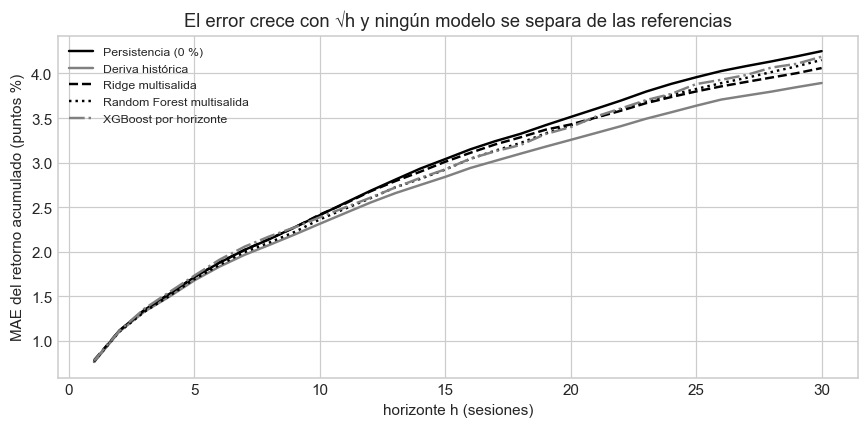

In [10]:
# Curva del MAE por horizonte (1 a 30) de los cinco pronósticos
plt.figure(figsize=(8, 4))
estilos = {
    "Persistencia (0 %)": ("black", "-"),
    "Deriva histórica": ("gray", "-"),
    "Ridge multisalida": ("black", "--"),
    "Random Forest multisalida": ("black", ":"),
    "XGBoost por horizonte": ("gray", "-."),
}
for nombre, P in preds.items():
    curva = [mean_absolute_error(Y_pru[f"h{h}"], P[:, h - 1]) for h in range(1, H + 1)]
    plt.plot(
        range(1, H + 1),
        curva,
        estilos[nombre][1],
        color=estilos[nombre][0],
        linewidth=1.6,
        label=nombre,
    )
plt.xlabel("horizonte h (sesiones)")
plt.ylabel("MAE del retorno acumulado (puntos %)")
plt.legend(fontsize=8)
plt.title("El error crece con √h y ningún modelo se separa de las referencias")
plt.tight_layout()
plt.show()

**Interpretación de resultados:** el **MAE** crece con el horizonte (aproximadamente como **√h**, la firma de una **caminata aleatoria**) y los tres modelos **no mejoran** de forma consistente a la **deriva histórica**; el acierto de signo a 30 sesiones se explica por la **tendencia alcista** del período (la mayoría de los tramos de 30 días son positivos), no por el modelo. Esto confirma, a 30 sesiones, lo visto a 1 día en las Guías 1 y 3: el **nivel** del retorno no se predice. Lo que **sí** se puede entregar con honestidad es el **rango** (Parte III).

# PARTE III — Intervalos de Pronóstico y su Cobertura

## 4. Dos Formas de Construir el Rango

**(a) Cuantiles empíricos:** sobre la **validación** se calculan, por horizonte, los percentiles 10 y 90 de los **residuos** del modelo elegido (Ridge). **(b) Cono de volatilidad:** el rango es **± z·σ_t·√h** con **σ_t = vol_22** del día (se **adapta** al riesgo actual) y **z = 1,28** para el 80 %. Se mide la **cobertura** real en la prueba: la fracción de retornos observados que cayó dentro del rango.

In [11]:
# (a) Cuantiles empíricos de los residuos de Ridge en la validación (ajuste solo con ent_a)
ridge_a = make_pipeline(StandardScaler(), Ridge(alpha=100)).fit(ent_a[VARS], ent_a[OBJ])
resid_val = val[OBJ].values - ridge_a.predict(val[VARS])
q10, q90 = np.percentile(resid_val, 10, axis=0), np.percentile(resid_val, 90, axis=0)
print(
    "Semiancho empírico del 80 % (puntos %):",
    {f"h{h}": round(float((q90[h - 1] - q10[h - 1]) / 2), 2) for h in hs},
)
# (b) Cono de volatilidad: z · vol_22 · sqrt(h)
z80 = 1.2816
cono = z80 * pru["vol_22"].values[:, None] * np.sqrt(np.arange(1, H + 1))[None, :]
print(
    "Semiancho del cono (mediana en la prueba, puntos %):",
    {f"h{h}": round(float(np.median(cono[:, h - 1])), 2) for h in hs},
)

Semiancho empírico del 80 % (puntos %): {'h1': 1.32, 'h5': 2.67, 'h10': 3.43, 'h20': 4.99, 'h30': 5.64}
Semiancho del cono (mediana en la prueba, puntos %): {'h1': 1.08, 'h5': 2.42, 'h10': 3.43, 'h20': 4.84, 'h30': 5.93}


In [12]:
# Cobertura real del 80 % nominal en la prueba, por horizonte, para los dos métodos (centro = pronóstico Ridge)
P_r = preds["Ridge multisalida"]
dentro_emp = (Y_pru.values >= P_r + q10) & (Y_pru.values <= P_r + q90)
dentro_cono = (Y_pru.values >= P_r - cono) & (Y_pru.values <= P_r + cono)
tabla_cob = pd.DataFrame(
    {
        "h": range(1, H + 1),
        "cobertura_empirica": dentro_emp.mean(0),
        "cobertura_cono_vol": dentro_cono.mean(0),
        "ancho_medio_emp": (q90 - q10),
        "ancho_medio_cono": 2 * cono.mean(0),
    }
)
print(tabla_cob[tabla_cob["h"].isin(hs)].round(3).to_string(index=False))
print(
    "Nominal: 0,80. Una cobertura menor indica rangos demasiado estrechos (la prueba "
    "fue más volátil que la validación)."
)

 h  cobertura_empirica  cobertura_cono_vol  ancho_medio_emp  ancho_medio_cono
 1               0.820               0.795            2.633             2.532
 5               0.786               0.789            5.333             5.662
10               0.770               0.794            6.865             8.007
20               0.787               0.801            9.979            11.323
30               0.758               0.804           11.274            13.868
Nominal: 0,80. Una cobertura menor indica rangos demasiado estrechos (la prueba fue más volátil que la validación).


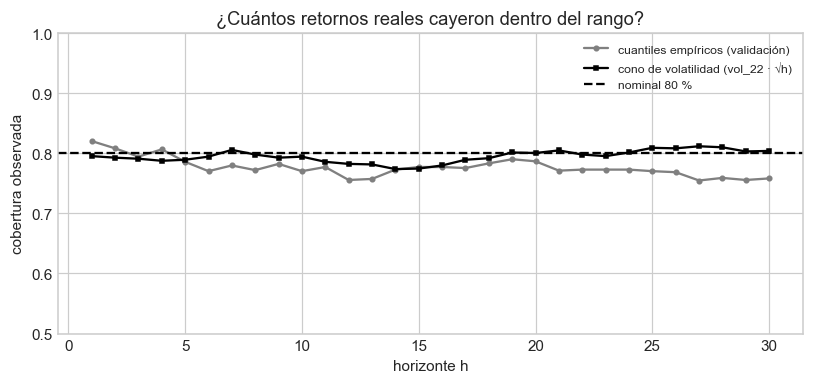

In [13]:
# Gráfico: cobertura por horizonte de los dos métodos frente al 80 % nominal
plt.figure(figsize=(7.5, 3.6))
plt.plot(
    tabla_cob["h"],
    tabla_cob["cobertura_empirica"],
    "o-",
    color="gray",
    markersize=3,
    label="cuantiles empíricos (validación)",
)
plt.plot(
    tabla_cob["h"],
    tabla_cob["cobertura_cono_vol"],
    "s-",
    color="black",
    markersize=3,
    label="cono de volatilidad (vol_22 · √h)",
)
plt.axhline(0.8, color="black", linestyle="--", label="nominal 80 %")
plt.ylim(0.5, 1.0)
plt.xlabel("horizonte h")
plt.ylabel("cobertura observada")
plt.legend(fontsize=8)
plt.title("¿Cuántos retornos reales cayeron dentro del rango?")
plt.tight_layout()
plt.show()

**Interpretación de resultados:** el rango **empírico** hereda la volatilidad del período de validación: si la prueba resulta más (o menos) agitada, la cobertura se aleja del **80 %**. El **cono de volatilidad** se **adapta** al riesgo del día y mantiene la cobertura más cerca del nominal en los horizontes cortos; en los largos (h ≥ 20) tiende a quedar **ancho o estrecho** según el régimen. **Moraleja:** en un sistema de pronóstico, el **rango** es la parte del producto que **sí** aporta información, y su **cobertura** es la métrica que hay que vigilar en producción (Tema 14: monitoreo).

# PARTE IV — Pronóstico Final, Calendario, JSON, CSV y Tablero

## 5. Reentrenar con Todo el Histórico y Proyectar 30 Sesiones desde el Último Cierre

In [14]:
# Reentrenamiento final con todas las filas que ya tienen sus 30 objetivos conocidos; pronóstico desde el último cierre disponible
final = make_pipeline(StandardScaler(), Ridge(alpha=100)).fit(datos[VARS], datos[OBJ])
ultima = X.dropna().iloc[
    [-1]
]  # última fila con variables completas (el último día de negociación)
fecha_corte = ultima.index[0]
ultimo_cierre = float(cierre.loc[fecha_corte])
ret_pred = final.predict(ultima[VARS])[0]
sigma_t = float(ultima["vol_22"].iloc[0])
banda = z80 * sigma_t * np.sqrt(np.arange(1, H + 1))
precio_central = ultimo_cierre * np.exp(ret_pred / 100)
precio_inf = ultimo_cierre * np.exp((ret_pred - banda) / 100)
precio_sup = ultimo_cierre * np.exp((ret_pred + banda) / 100)
print(
    f"Fecha de corte: {fecha_corte.date()} | último cierre de SPY = "
    f"{ultimo_cierre:.2f} USD | vol_22 = {sigma_t:.3f} % diario | VIX = "
    f"{float(ultima['vix'].iloc[0]):.2f}"
)
print(
    f"Retorno acumulado pronosticado: h1 = {ret_pred[0]:+.3f} % | h5 = "
    f"{ret_pred[4]:+.3f} % | h10 = {ret_pred[9]:+.3f} % | h20 = {ret_pred[19]:+.3f} % "
    f"| h30 = {ret_pred[29]:+.3f} %"
)
print(
    f"Precio central a 30 sesiones = {precio_central[-1]:.2f} USD | rango 80 % = "
    f"[{precio_inf[-1]:.2f}, {precio_sup[-1]:.2f}] USD"
)

Fecha de corte: 2026-11-11 | último cierre de SPY = 759.81 USD | vol_22 = 1.372 % diario | VIX = 17.49
Retorno acumulado pronosticado: h1 = -0.403 % | h5 = -0.554 % | h10 = -0.177 % | h20 = +0.537 % | h30 = +0.805 %
Precio central a 30 sesiones = 765.95 USD | rango 80 % = [695.63, 843.39] USD


In [15]:
# Calendario bursátil aproximado: días hábiles de lunes a viernes sin los feriados de la NYSE (lista explícita)
feriados_nyse = pd.to_datetime(
    [
        "2026-11-26",
        "2026-12-25",
        "2027-01-01",
        "2027-01-18",
        "2027-02-15",
        "2027-03-26",
        "2027-05-31",
        "2027-06-18",
        "2027-07-05",
        "2027-09-06",
        "2027-11-25",
        "2027-12-24",
    ]
)
fechas = pd.bdate_range(
    fecha_corte + pd.Timedelta(days=1),
    periods=H + 10,
    freq="C",
    holidays=list(feriados_nyse),
)[:H]
pronostico = pd.DataFrame(
    {
        "fecha": fechas.strftime("%Y-%m-%d"),
        "h": range(1, H + 1),
        "retorno_acum_pct": ret_pred.round(4),
        "precio_central": precio_central.round(2),
        "precio_inf_80": precio_inf.round(2),
        "precio_sup_80": precio_sup.round(2),
    }
)
print(pronostico.iloc[[0, 4, 9, 19, 29]].to_string(index=False))
print(
    "Nota: el calendario excluye fines de semana y los feriados listados; verifique "
    "el calendario oficial de la NYSE."
)

     fecha  h  retorno_acum_pct  precio_central  precio_inf_80  precio_sup_80
2026-11-12  1           -0.4026          756.76         743.57         770.18
2026-11-18  5           -0.5540          755.61         726.48         785.91
2026-11-25 10           -0.1769          758.47         717.44         801.83
2026-12-10 20            0.5370          763.90         706.13         826.40
2026-12-24 30            0.8053          765.95         695.63         843.39
Nota: el calendario excluye fines de semana y los feriados listados; verifique el calendario oficial de la NYSE.


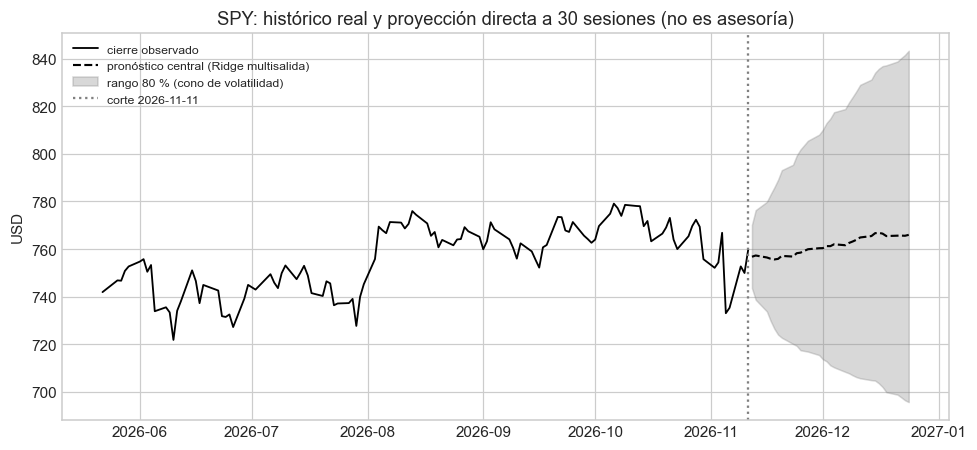

In [16]:
# Gráfico final: últimos 120 cierres observados, pronóstico central y rango 80 %
plt.figure(figsize=(9, 4.2))
hist = cierre.loc[:fecha_corte].tail(120)
plt.plot(
    hist.index, hist.values, color="black", linewidth=1.2, label="cierre observado"
)
plt.plot(
    fechas,
    precio_central,
    "--",
    color="black",
    linewidth=1.4,
    label="pronóstico central (Ridge multisalida)",
)
plt.fill_between(
    fechas,
    precio_inf,
    precio_sup,
    color="gray",
    alpha=0.3,
    label="rango 80 % (cono de volatilidad)",
)
plt.axvline(
    fecha_corte, color="gray", linestyle=":", label=f"corte {fecha_corte.date()}"
)
plt.ylabel("USD")
plt.legend(fontsize=8)
plt.title("SPY: histórico real y proyección directa a 30 sesiones (no es asesoría)")
plt.tight_layout()
plt.show()

## 6. Exportar el Sistema: JSON para la API, CSV para el Informe y Tablero HTML

In [17]:
# Archivos de salida del sistema (se crean en el directorio de trabajo; en Colab, descárguelos desde el panel de archivos)
hist_json = [
    {
        "fecha": d.strftime("%Y-%m-%d"),
        "open": round(float(o), 2),
        "high": round(float(h_), 2),
        "low": round(float(l), 2),
        "close": round(float(c), 2),
    }
    for d, o, h_, l, c in spy.loc[:fecha_corte]
    .tail(250)[["Open", "High", "Low", "Close"]]
    .itertuples()
]
salida = {
    "instrumento": "SPY",
    "fecha_corte": fecha_corte.strftime("%Y-%m-%d"),
    "ultimo_cierre": round(ultimo_cierre, 2),
    "modelo": "Ridge multisalida (alpha = 100) sobre 13 variables causales; rango = 1,28 · vol_22 · sqrt(h)",
    "generado": pd.Timestamp.today().strftime("%Y-%m-%d %H:%M"),
    "metricas_prueba": {
        fila["modelo"]: {f"MAE_h{h}": round(float(fila[f"MAE_h{h}"]), 4) for h in hs}
        for _, fila in tabla_h.iterrows()
    },
    "cobertura_80_cono": {
        f"h{h}": round(float(tabla_cob.loc[h - 1, "cobertura_cono_vol"]), 3) for h in hs
    },
    "historico": hist_json,
    "pronostico": pronostico.to_dict(orient="records"),
    "aviso": "Material académico (UNMSM, Minería de Datos). No es asesoría de inversión.",
}
json.dump(
    salida,
    open("dashboard_regresion_spy.json", "w", encoding="utf-8"),
    ensure_ascii=False,
    indent=1,
)
pronostico.to_csv("pronostico_30_sesiones_spy.csv", index=False)
print(
    "Escritos: dashboard_regresion_spy.json (",
    len(hist_json),
    "velas +",
    H,
    "pronósticos ) y pronostico_30_sesiones_spy.csv",
)

Escritos: dashboard_regresion_spy.json ( 250 velas + 30 pronósticos ) y pronostico_30_sesiones_spy.csv


In [18]:
# Tablero HTML de un solo archivo con los datos incrustados (velas, pronóstico, rango, alerta de precio); usa ECharts desde CDN
plantilla = r"""<!DOCTYPE html><html lang="es"><head><meta charset="utf-8"><title>SPY · Pronóstico a 30 sesiones</title>
<script src="https://cdnjs.cloudflare.com/ajax/libs/echarts/5.5.1/echarts.min.js"></script>
<style>body{font-family:Calibri,Arial,sans-serif;margin:16px;background:#fff;color:#000}h1{color:#1F3864;font-size:22px;margin:0 0 4px}
.sub{color:#800000;font-weight:bold}.fila{display:flex;gap:16px;flex-wrap:wrap;align-items:center;margin:8px 0}
table{border-collapse:collapse;font-size:13px}td,th{border:1px solid #BFBFBF;padding:3px 8px;text-align:right}th{color:#1F3864}
#g{width:100%;height:480px;border:1px solid #BFBFBF}.aviso{font-size:12px;color:#333}button{padding:4px 10px}</style></head><body>
<h1>SPY · Sistema de pronóstico directo a 30 sesiones</h1><div class="sub" id="sub"></div>
<div class="fila"><label>Alerta si el precio central supera: <input id="umbral" type="number" step="1" style="width:90px"></label>
<button onclick="alerta()">Evaluar</button><span id="msg"></span><button onclick="tema=tema=='light'?'dark':'light';dibujar()">Tema claro/oscuro</button></div>
<div id="g"></div>
<h3 style="color:#800000">Error absoluto medio del retorno acumulado en la prueba (puntos %)</h3><div id="tabla"></div>
<p class="aviso" id="aviso"></p>
<script>const D=__DATOS__;let tema='light';
document.getElementById('sub').textContent='Corte '+D.fecha_corte+' · último cierre '+D.ultimo_cierre+' USD · '+D.modelo;
document.getElementById('aviso').textContent=D.aviso+' Generado: '+D.generado+'. Cobertura 80 % del cono en la prueba: '+JSON.stringify(D.cobertura_80_cono);
function dibujar(){const el=document.getElementById('g');echarts.dispose(el);const ch=echarts.init(el,tema==='dark'?'dark':null);
const fechas=D.historico.map(x=>x.fecha).concat(D.pronostico.map(x=>x.fecha));const n=D.historico.length;
const velas=D.historico.map(x=>[x.open,x.close,x.low,x.high]);const nul=D.historico.map(()=>null);
const central=nul.slice(0,n-1).concat([D.ultimo_cierre]).concat(D.pronostico.map(x=>x.precio_central));
const inf=nul.slice(0,n-1).concat([D.ultimo_cierre]).concat(D.pronostico.map(x=>x.precio_inf_80));
const sup=nul.slice(0,n-1).concat([D.ultimo_cierre]).concat(D.pronostico.map(x=>x.precio_sup_80));
ch.setOption({backgroundColor:tema==='dark'?'#111':'#fff',tooltip:{trigger:'axis'},legend:{data:['Velas observadas','Pronóstico central','Rango 80 % (inferior)','Rango 80 % (superior)']},
xAxis:{type:'category',data:fechas},yAxis:{scale:true,name:'USD'},dataZoom:[{type:'inside',start:60},{start:60}],
series:[{name:'Velas observadas',type:'candlestick',data:velas,itemStyle:{color:'#1B7E34',color0:'#800000',borderColor:'#1B7E34',borderColor0:'#800000'}},
{name:'Pronóstico central',type:'line',data:central,lineStyle:{type:'dashed',width:2,color:'#1F3864'},showSymbol:false},
{name:'Rango 80 % (inferior)',type:'line',data:inf,lineStyle:{width:1,color:'#C5961A'},showSymbol:false},
{name:'Rango 80 % (superior)',type:'line',data:sup,lineStyle:{width:1,color:'#C5961A'},areaStyle:{color:'rgba(197,150,26,0.15)'},showSymbol:false}]});}
function alerta(){const u=parseFloat(document.getElementById('umbral').value);const p=D.pronostico;const sup=p.filter(x=>x.precio_central>u);
document.getElementById('msg').textContent=isNaN(u)?'Ingrese un umbral':(sup.length?'El pronóstico central supera '+u+' USD desde '+sup[0].fecha+' (h='+sup[0].h+')':'Ningún día del pronóstico central supera '+u+' USD');}
const t=document.getElementById('tabla');let h='<table><tr><th>modelo</th>';const hs=['MAE_h1','MAE_h5','MAE_h10','MAE_h20','MAE_h30'];hs.forEach(k=>h+='<th>'+k+'</th>');h+='</tr>';
for(const m in D.metricas_prueba){h+='<tr><td style="text-align:left">'+m+'</td>';hs.forEach(k=>h+='<td>'+D.metricas_prueba[m][k].toFixed(3)+'</td>');h+='</tr>';}t.innerHTML=h+'</table>';
document.getElementById('umbral').value=Math.round(D.ultimo_cierre*1.02);dibujar();</script></body></html>"""
html = plantilla.replace("__DATOS__", json.dumps(salida, ensure_ascii=False))
open("08_Tablero_Pronostico_SPY_30_sesiones.html", "w", encoding="utf-8").write(html)
print(
    "Escrito: 08_Tablero_Pronostico_SPY_30_sesiones.html (",
    len(html) // 1024,
    "KB ) -> ábralo en un navegador con Internet (ECharts por CDN)",
)

Escrito: 08_Tablero_Pronostico_SPY_30_sesiones.html ( 30 KB ) -> ábralo en un navegador con Internet (ECharts por CDN)


**Interpretación de resultados:** el sistema entrega **tres artefactos**: el **JSON** (que una API Flask puede servir en `/api/dashboard`), el **CSV** del pronóstico y el **tablero** con velas reales, pronóstico central, rango del 80 % y una alerta de precio. El tablero **no** consulta cotizaciones en vivo: muestra lo que el notebook calculó en la fecha de corte. Un despliegue real exigiría **reentrenar** cada día, **monitorear la cobertura** del rango y **versionar** el modelo (Tema 14).

**Advertencia:** el **pronóstico central** a 30 sesiones es, en la práctica, la **deriva histórica** (unas décimas de punto por semana); su valor informativo está en el **rango**, no en el punto.

## 7. Actividad Autónoma

1. Cambie `alpha` de Ridge a 1 y 1000 y repita la tabla de MAE por horizonte. ¿Cambia algo de forma significativa?
2. Reemplace el cono de **vol_22** por uno basado en el **VIX** (σ = VIX/√252) y compare la **cobertura** por horizonte.
3. Genere el sistema completo para **QQQ** (o para una acción de su portafolio del TG11) y cargue su JSON en el tablero.

**Entregable:** notebook ejecutado, los tres archivos exportados y un párrafo (≤ 150 palabras) sobre qué parte del sistema entregaría a un comité de inversiones y qué parte no.